# Options strategies: the view, the construction, the greeks

Notebook 09 used one strategy, the straddle. Desks use many more, all built from the same
bricks: calls and puts, bought or sold, at one or several strikes and maturities.

Each strategy is read with the same grid:

- **the view**: what the trader expects from the market;
- **the construction**: which options, bought or sold;
- **value and greeks** against the future price (today, and at expiry dashed);
- **who uses it**, in commodities.

1. Volatility: straddle, strangle, butterfly
2. Direction: call spread, put spread
3. Hedging a production: collar (and risk reversal), seagull
4. Time: calendar spread
5. All of them side by side
6. The others, in one table

Brent future at 75 $, implied vol 32 % for every strike (no smile yet), 1 bbl per option,
Black-76 with QuantLib.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import QuantLib as ql

from cmdty import MarketData, Quote
from cmdty.models.black76 import analytic_greeks, expected_payoff
from cmdty.plotting import (MUTED, SERIES, plot_delta, plot_gamma, plot_theta, plot_value,
                            plot_vega, use_style)
from cmdty.strategies import (butterfly, calendar_spread, call_spread, collar, put_spread,
                              risk_reversal, seagull, straddle, strangle)

use_style()

TODAY = ql.Date(27, 11, 2026)
F0, VOL = 75.0, 0.32
U, CONTRACT = "BRENT", "2027-03"
EXP, NEAR = "2027-02-26", "2026-12-28"  # 3 months, 1 month
F = np.linspace(50, 100, 201)


def market_at(f: float, date: ql.Date = TODAY) -> MarketData:
    return MarketData(today=date, rate=0.04, quotes={U: Quote(f, VOL)})


def value(trades, f: float, date: ql.Date = TODAY) -> float:
    """Value of the strategy per bbl (Black-76, QuantLib, undiscounted). Expired legs: payoff."""
    m = market_at(f, date)
    return sum(t.instrument.quantity * expected_payoff(t.instrument, m) for t in trades)


def greeks(trades, f: float) -> dict:
    """Delta, gamma, vega ($/vol point), theta ($/day) of the strategy, per bbl."""
    m = market_at(f)
    g = [(t.instrument.quantity, analytic_greeks(t.instrument, m)) for t in trades]
    return dict(delta=sum(q * x.delta for q, x in g), gamma=sum(q * x.gamma for q, x in g),
                vega=sum(q * x.vega for q, x in g),
                theta=value(trades, f, TODAY + 1) - value(trades, f))


def first_expiry(trades) -> ql.Date:
    return min(t.instrument.expiry for t in trades)


def show(trades, title: str, view: str):
    """Value (today and at the first expiry) and the four greeks against the future price."""
    today = [value(trades, f) for f in F]
    at_expiry = [value(trades, f, first_expiry(trades)) for f in F]
    g = [greeks(trades, f) for f in F]
    premium = value(trades, F0)
    fig, axes = plt.subplots(1, 5, figsize=(19, 3.8))
    plot_value(F, {"today": today}, payoff=at_expiry, f0=F0, ax=axes[0], title=title,
               subtitle=f"{view}; premium {premium:+.2f} $/bbl", legend=False)
    for ax, (name, plot) in zip(axes[1:], [("delta", plot_delta), ("gamma", plot_gamma),
                                           ("vega", plot_vega), ("theta", plot_theta)]):
        plot(F, [x[name] for x in g], f0=F0, ax=ax, subtitle=f"{g[100][name]:+.3f} at 75")
    for ax in axes[1:]:
        ax.set_xlabel("")
    fig.tight_layout(w_pad=1.5)
    plt.show()

How to read each row of charts: the first panel is the value per bbl, **today** (solid) and
**at expiry** (dashed); the premium is what the strategy costs today (+ = paid, − = received).
The other four panels are its greeks against the future price, with today's value at 75 in the
subtitle.

## 1. Volatility: straddle, strangle, butterfly

### Straddle: buy call 75 + put 75

**View**: the Brent will move a lot, direction unknown. **Used by**: vol traders (notebook 09).

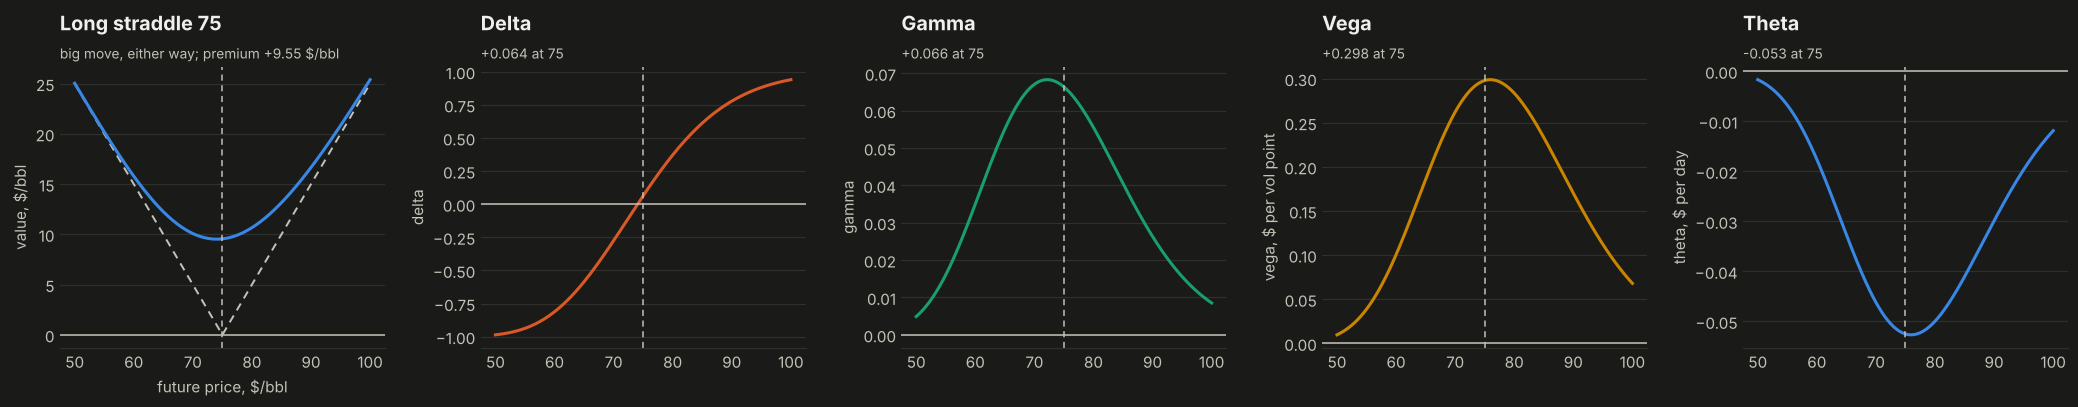

In [2]:
show(straddle(U, CONTRACT, EXP, 75.0, 1), "Long straddle 75", "big move, either way")

Long gamma and vega everywhere, delta about 0 at 75, the most theta to pay. The dashed V: at
expiry it pays the distance to 75.

### Strangle: buy put 68 + call 82

**View**: a very big move. **Construction**: the straddle with the two strikes pulled apart.
**Used by**: vol traders who want a cheaper ticket.

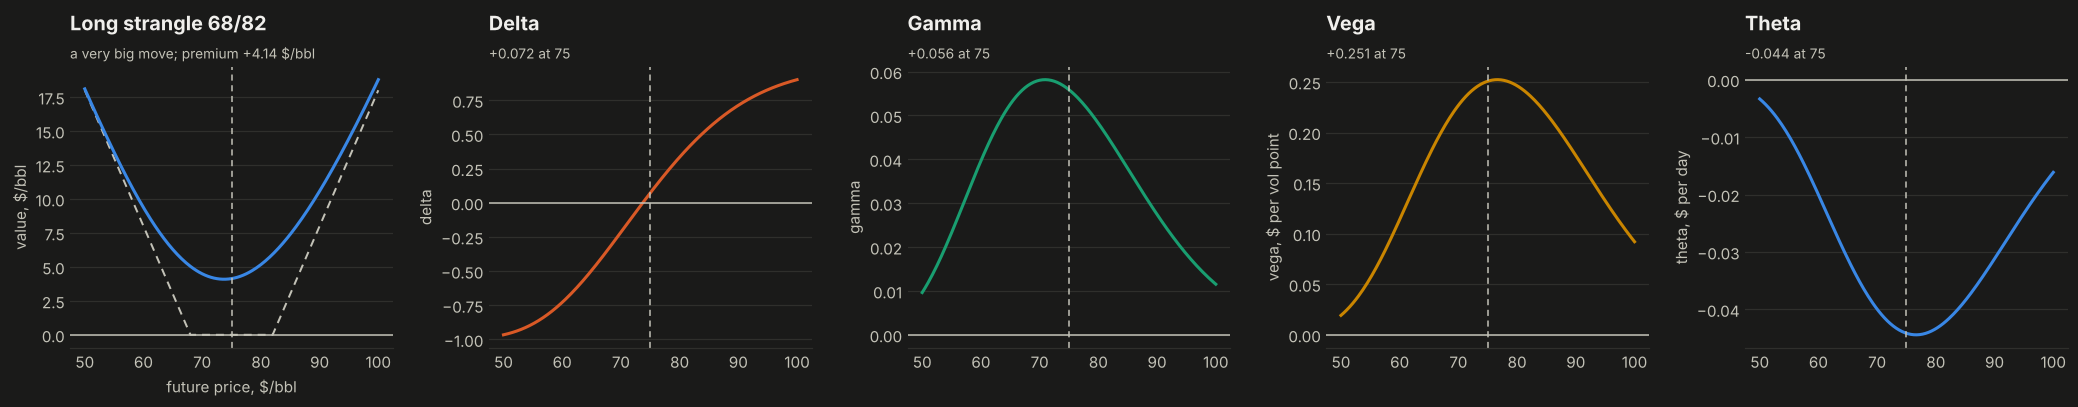

In [3]:
show(strangle(U, CONTRACT, EXP, 68.0, 82.0, 1), "Long strangle 68/82", "a very big move")

Cheaper than the straddle, but nothing at expiry between 68 and 82: the Brent has to travel
further. Its gamma is spread out, lower at 75, and its theta is smaller.

### Butterfly: buy call 68, sell 2 calls 75, buy call 82

**View**: the Brent stays near 75. **Construction**: a bought call spread 68/75 plus a sold call
spread 75/82. **Used by**: traders selling vol with a limited loss (a sold straddle loses
without limit, the butterfly cannot lose more than its premium).

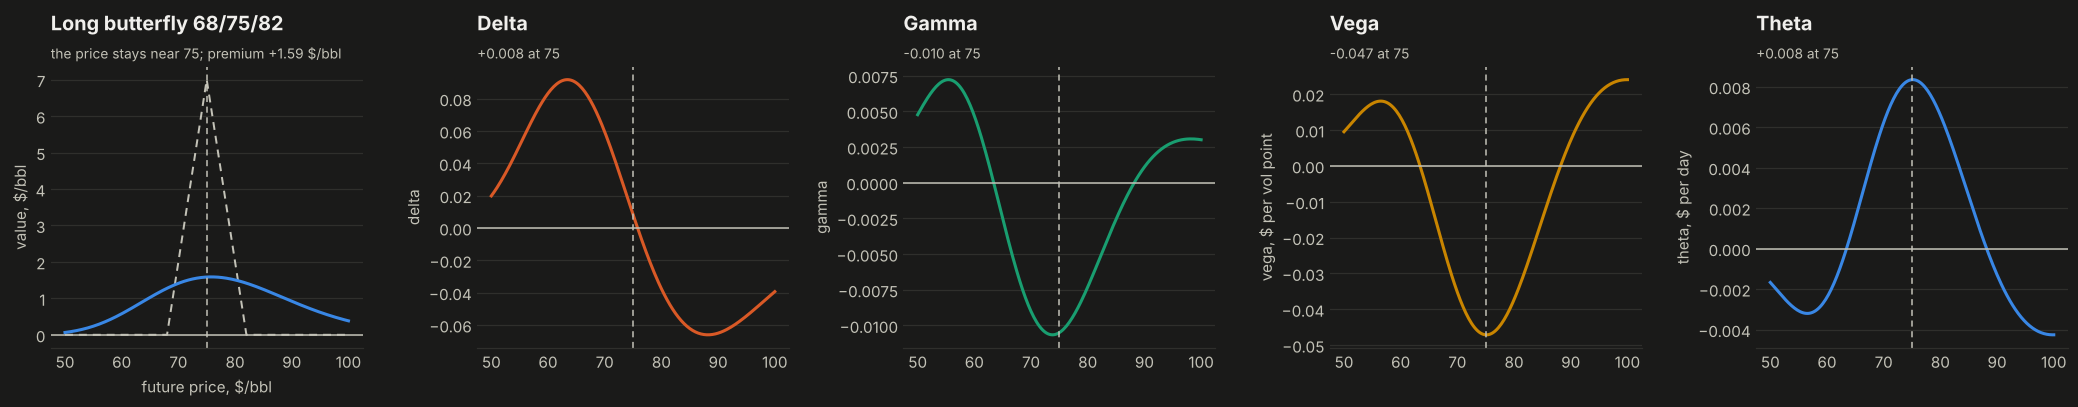

In [4]:
show(butterfly(U, CONTRACT, EXP, 68.0, 75.0, 82.0, 1), "Long butterfly 68/75/82",
     "the price stays near 75")

The tent at expiry peaks at 75. Around 75 it is **short gamma and short vega, and collects
theta**: the mirror of the straddle there, but bounded on both sides.

## 2. Direction: call spread, put spread

### Call spread: buy call 75, sell call 85

**View**: a moderate rise, up to 85. **Construction**: the sold call pays for part of the
bought one, in exchange for capping the gain at 85. **Used by**: buyers of crude (refiners,
airlines through jet) who want protection against a rise without paying a full call.

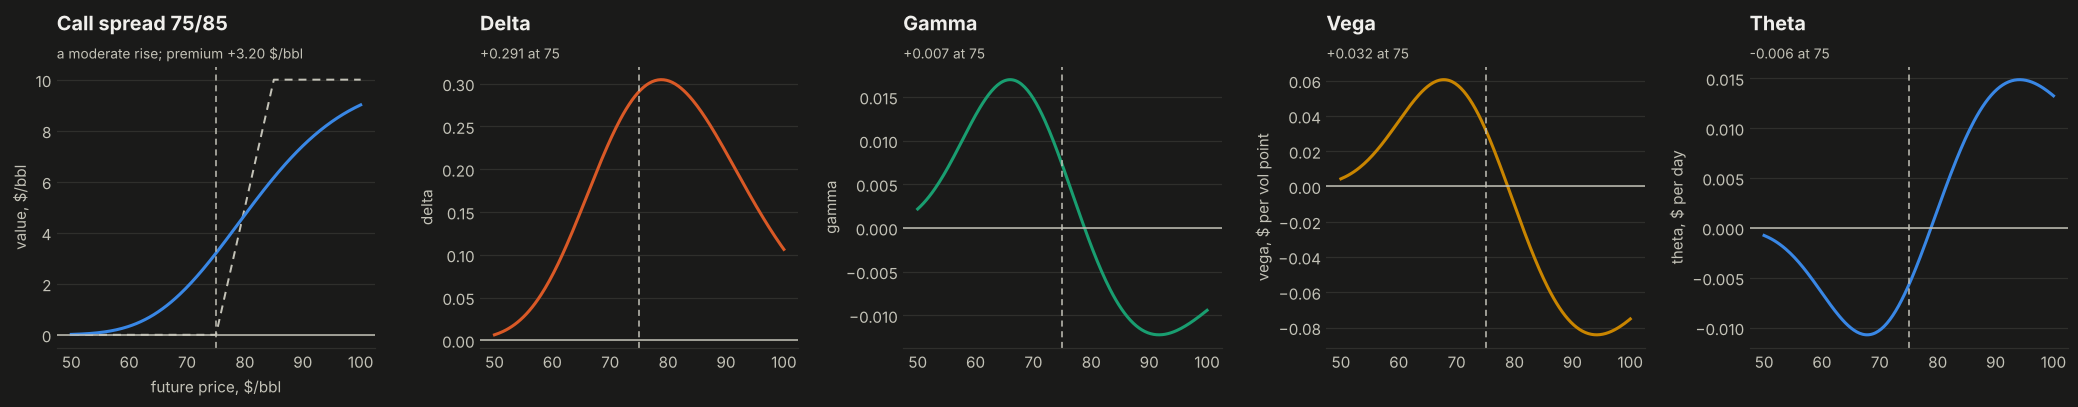

In [5]:
show(call_spread(U, CONTRACT, EXP, 75.0, 85.0, 1), "Call spread 75/85", "a moderate rise")

Delta + but capped; gamma changes sign between the strikes (long near 75, short near 85).

### Put spread: buy put 75, sell put 65

**View**: a moderate fall, down to 65. **Used by**: producers who want a floor for a limited
fall, cheaper than a put.

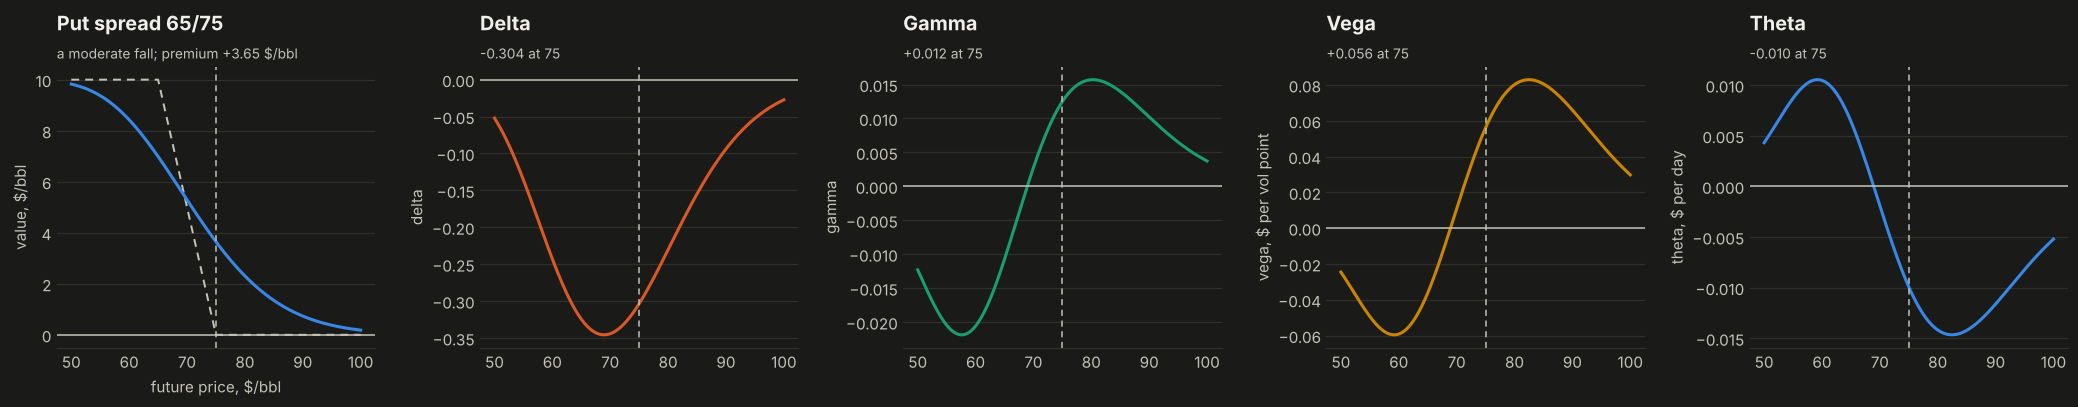

In [6]:
show(put_spread(U, CONTRACT, EXP, 65.0, 75.0, 1), "Put spread 65/75", "a moderate fall")

## 3. Hedging a production: collar, seagull

A producer sells oil: it **is long the Brent** and fears a fall. The strategies below are what it
adds to its production.

### Collar: buy put 68, sell call 82

**View**: protect against a fall below 68, accept giving up the rise above 82. **Construction**:
the sold call pays for the put, often for close to zero premium. **Used by**: producers, the most
common oil hedge.

The **risk reversal** is the same two options the other way round (buy the call, sell the put):
a consumer's collar, or a bet on the skew.

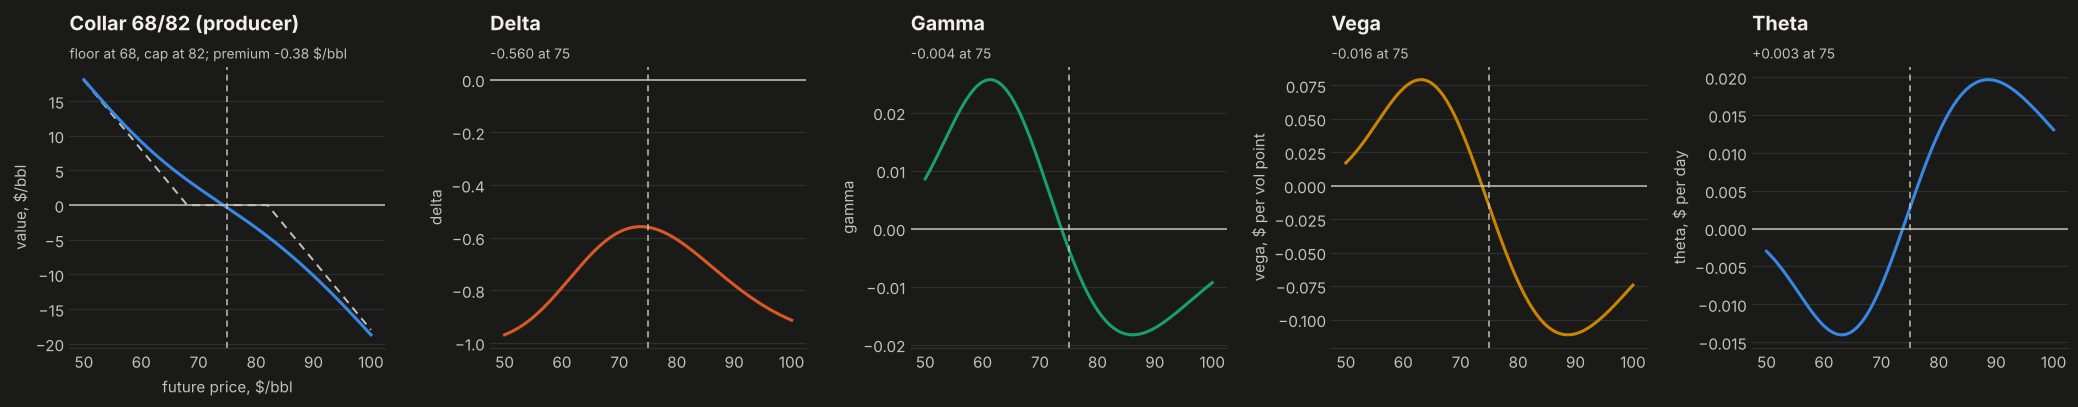

In [7]:
show(collar(U, CONTRACT, EXP, 68.0, 82.0, 1), "Collar 68/82 (producer)",
     "floor at 68, cap at 82")

Delta −: it offsets the producer's long oil. Gamma and vega change sign along the price axis:
long below (the bought put), short above (the sold call). Premium close to zero: here a small
credit (0.38 $/bbl), because with one vol for all strikes the call 82 is worth a bit more than the
put 68. With a real smile, puts are dearer and the balance moves.

### Seagull: sell put 60, buy put 70, sell call 82

**View**: protection between 70 and 60, at zero cost or even a credit. **Construction**: a collar
plus a sold put far below the floor. **Used by**: producers, very common in oil. The catch: below
60 the protection stops, the producer is exposed again to a crash.

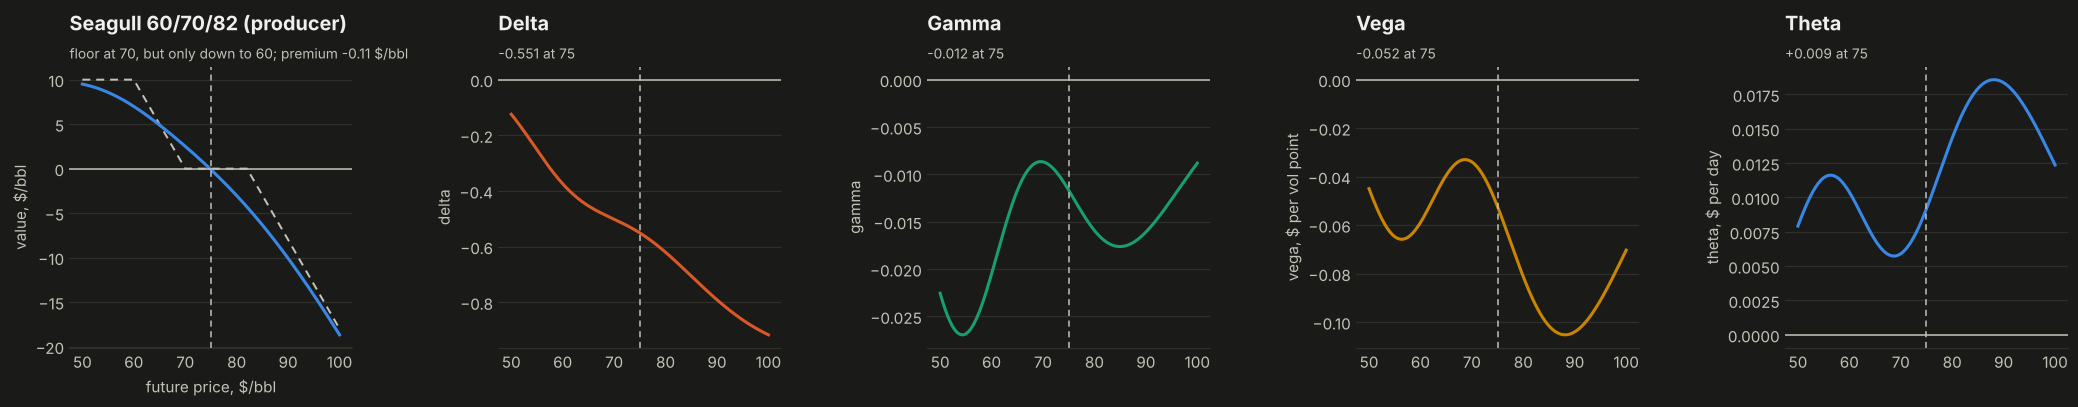

In [8]:
show(seagull(U, CONTRACT, EXP, 60.0, 70.0, 82.0, 1), "Seagull 60/70/82 (producer)",
     "floor at 70, but only down to 60")

What the producer earns per barrel at expiry, oil sold plus hedge (premium included):

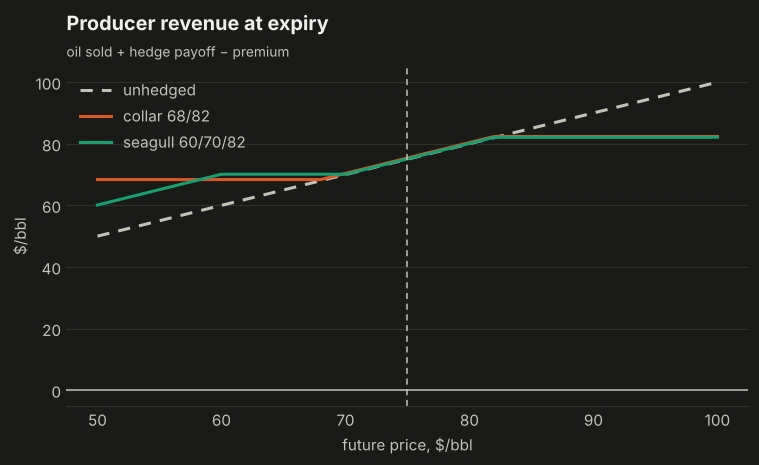

In [9]:
expiry = ql.DateParser.parseISO(EXP)
hedges = {"collar 68/82": collar(U, CONTRACT, EXP, 68.0, 82.0, 1),
          "seagull 60/70/82": seagull(U, CONTRACT, EXP, 60.0, 70.0, 82.0, 1)}
revenue = {"unhedged": F}
for name, trades in hedges.items():
    premium = value(trades, F0)
    revenue[name] = F + np.array([value(trades, f, expiry) for f in F]) - premium
ax = plot_value(F, revenue, f0=F0, title="Producer revenue at expiry", ylabel="$/bbl",
                subtitle="oil sold + hedge payoff − premium",
                styles={"unhedged": {"color": MUTED, "linestyle": (0, (4, 3))}})
ax.legend(frameon=False, loc="upper left")
plt.show()

- **Collar**: revenue never below about 68, never above about 82. A band.
- **Seagull**: same floor at 70, but below 60 the revenue falls again with the market. Cheaper
  (or a credit), and dangerous in a crash, which is exactly when the protection was needed.

## 4. Time: calendar spread

### Calendar spread: sell call 75 at 1 month, buy call 75 at 3 months

**View**: the price stays near 75 for a month, and the 3-month vol holds or rises.
**Construction**: two calls at the same strike, different maturities. **Used by**: vol traders,
to collect the fast theta of the short option while staying long vega.

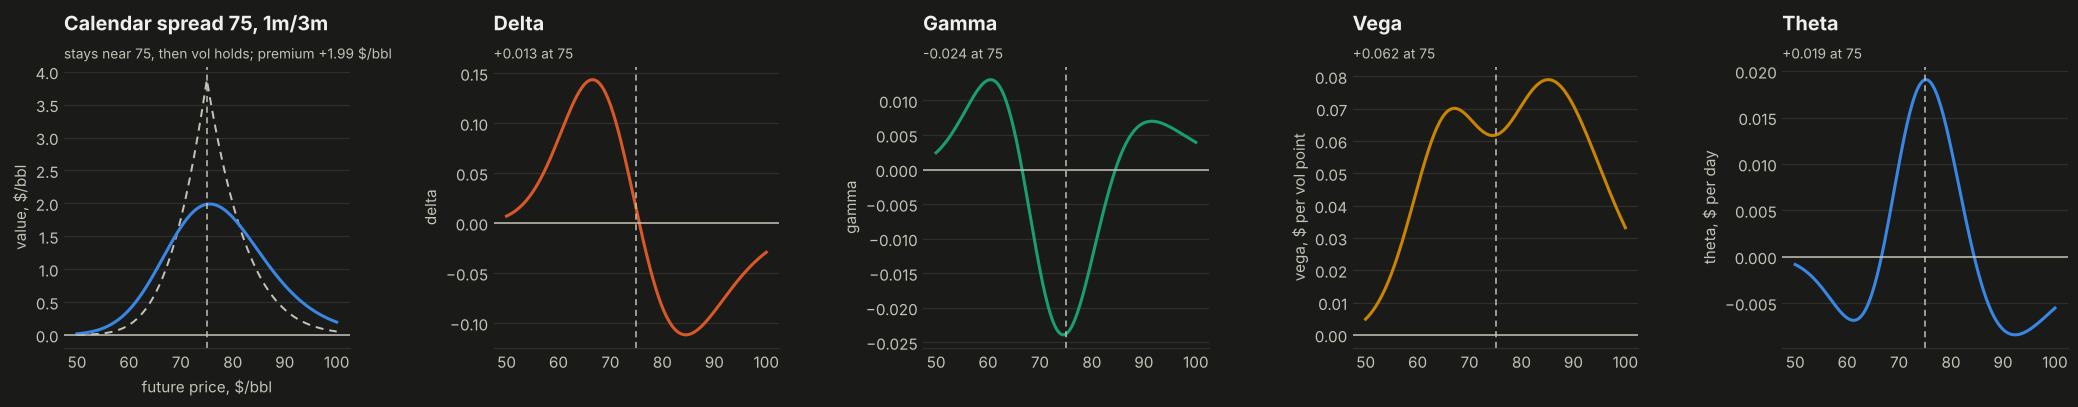

In [10]:
show(calendar_spread(U, CONTRACT, NEAR, EXP, 75.0, 1), "Calendar spread 75, 1m/3m",
     "stays near 75, then vol holds")

The dashed curve is the value when the 1-month call expires: the 3-month call is still alive,
so it is a curve, highest at 75. Today the spread is **short gamma** (the 1-month option has the
most gamma) but **long vega** (the 3-month option has the most vega) and **collects theta**:
gamma and vega no longer go together, the maturity separates them (notebook 07, section 2).

## 5. All of them side by side

Greeks at 75 per bbl, and the premium (+ paid, − received).

In [11]:
strategies = {
    "long straddle 75": straddle(U, CONTRACT, EXP, 75.0, 1),
    "long strangle 68/82": strangle(U, CONTRACT, EXP, 68.0, 82.0, 1),
    "long butterfly 68/75/82": butterfly(U, CONTRACT, EXP, 68.0, 75.0, 82.0, 1),
    "call spread 75/85": call_spread(U, CONTRACT, EXP, 75.0, 85.0, 1),
    "put spread 65/75": put_spread(U, CONTRACT, EXP, 65.0, 75.0, 1),
    "collar 68/82": collar(U, CONTRACT, EXP, 68.0, 82.0, 1),
    "risk reversal 68/82": risk_reversal(U, CONTRACT, EXP, 68.0, 82.0, 1),
    "seagull 60/70/82": seagull(U, CONTRACT, EXP, 60.0, 70.0, 82.0, 1),
    "calendar 75 1m/3m": calendar_spread(U, CONTRACT, NEAR, EXP, 75.0, 1),
}
rows = {name: {"premium": value(t, F0), **greeks(t, F0)} for name, t in strategies.items()}
table = pd.DataFrame(rows).T
band = {"delta": 0.1, "gamma": 1e-3, "vega": 1e-3, "theta": 1e-3}  # delta ≈ 0 within ±0.1
signs = table.drop(columns="premium").apply(
    lambda col: col.map(lambda x: "+" if x > band[col.name] else ("−" if x < -band[col.name] else "≈ 0")))
pd.concat({"at 75, per bbl": table.round(3), "sign": signs}, axis=1)

at 75, per bbl                              sign  \
                               premium  delta  gamma   vega  theta delta   
long straddle 75                 9.551  0.064  0.066  0.298 -0.053   ≈ 0   
long strangle 68/82              4.136  0.072  0.056  0.251 -0.044   ≈ 0   
long butterfly 68/75/82          1.585  0.008 -0.010 -0.047  0.008   ≈ 0   
call spread 75/85                3.200  0.291  0.007  0.032 -0.006     +   
put spread 65/75                 3.648 -0.304  0.012  0.056 -0.010     −   
collar 68/82                    -0.376 -0.560 -0.004 -0.016  0.003     −   
risk reversal 68/82              0.376  0.560  0.004  0.016 -0.003     +   
seagull 60/70/82                -0.112 -0.551 -0.012 -0.052  0.009     −   
calendar 75 1m/3m                1.986  0.013 -0.024  0.062  0.019   ≈ 0   

                                          
                        gamma vega theta  
long straddle 75            +    +     −  
long strangle 68/82         +    +     −  
long butterfly 68/75/82     −    −     +  
call spread 75/85           +    +     −  
put spread 65/75            +    +     −  
collar 68/82                −    −     +  
risk reversal 68/82         +    +     −  
seagull 60/70/82            −    −     +  
calendar 75 1m/3m           −    +     +

Reading the sign columns:

- **Gamma and theta always have opposite signs**: what is long gamma pays theta.
- **Vega usually follows gamma**, except for the calendar spread, where two maturities split
  them.
- **Delta** says the direction: about 0 for the vol strategies, + or − for the directional and
  hedging ones.

## 6. The others, in one table

All built from the same bricks.

| Strategy | Construction | View / use |
|---|---|---|
| Condor | butterfly with two middle strikes (buy K1, sell K2, sell K3, buy K4) | the price stays in a range, wider than a butterfly |
| Iron butterfly | sell straddle K, buy strangle around it | same view as a butterfly, built with calls and puts |
| Iron condor | sell strangle, buy a wider strangle | stays in a range, limited loss |
| Ratio spread (1×2) | buy 1 call K1, sell 2 calls K2 | moderate rise, cheap or free, loses on a big rise |
| Backspread | sell 1 call K1, buy 2 calls K2 | a big rise, little cost if wrong |
| Synthetic long / short | buy call K + sell put K (or the reverse) | a future made of options (put-call parity) |
| Protective put | own the commodity + buy a put | a floor on a stock or a cargo |
| Covered call | own the commodity + sell a call | earn premium, give up the upside |
| Three-way / fence | other names for the seagull | producer hedges |
| Diagonal spread | calendar spread with different strikes | time plus a directional tilt |
| Strip / strap | straddle with 2 puts (strip) or 2 calls (strap) | a big move, more likely one way |
| Asian option (APO) | option on an average price (in this repo) | hedges a flow priced on a monthly average |
| Spread options | option on a difference: crack (product − crude), spark (power − gas), calendar spread option (month − month) | margins and time spreads |
| Swing option | the right to vary daily volumes within limits | gas and power supply contracts |
| Barrier options | an option that switches on or off at a level | cheaper hedges with conditions |

Next step: the vol smile, where each strike has its own implied vol. It changes the cost of every
strategy here with strikes away from 75 (collar, seagull, risk reversal above all).